# ARX models of experimental data of Borgerskolen

In [1]:
import numpy as np
import cvxopt
import scipy.stats as ss
from scipy.linalg import expm
import scipy.optimize as optim
import scipy.interpolate as si
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.integrate import odeint
import datetime as dt
import glob
import seaborn as sns
import numdifftools as numdif
import statsmodels.api as sm
import pandas as pd
import statsmodels.nonparametric.kernel_regression as kernelreg
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
import pickle
#plt.rc('text', usetex=True)
import csaps
import gzip
from datetime import datetime, timedelta
from os import path
import os
import requests
import zipfile
from io import StringIO
import json
import copy
plt.rc('text', usetex=True)


In [2]:
def load_DMI_data(return_timestamps = False, from_date=None):
    stationId = '06188' # Sjælsmark
    #stationId = '30414' # Roskilde
    #timestamp = "20190413"
    fromtimestamp = "20210228"
    _now = datetime.now()
    _datenow = _now.strftime("%Y%m%d")
    #totimestamp = _datenow
    totimestamp = "20210328"
    fromtime = str(int(datetime.strptime(fromtimestamp, "%Y%m%d").timestamp() * 1000000))
    totime = str(int(datetime.strptime(totimestamp, "%Y%m%d").timestamp() * 1000000))

    website_temp = 'https://dmigw.govcloud.dk/metObs/v1/observation?parameterId=temp_mean_past1h&stationId=' + stationId +\
                                    '&from=' + fromtime + '&to=' + totime + '&limit=100000000&api-key=<DMI_API_KEY>'
    resp_temp = requests.get(url=website_temp)
    data_temp_json = resp_temp.json()

    website_radia = 'https://dmigw.govcloud.dk/metObs/v1/observation?parameterId=radia_glob&stationId=' + stationId +\
                                    '&from=' + fromtime + '&to=' + totime + '&limit=100000000&api-key=<DMI_API_KEY>'
    resp_radia = requests.get(url=website_radia)
    data_radia_json = resp_radia.json()
    
    # Fill in missing observations of the solar radiation
    count = 0
    for i in range(len(data_radia_json)-1):
        date1 = datetime.fromtimestamp(data_radia_json[i+count]['timeObserved']/1000000) # newest
        date2 = datetime.fromtimestamp(data_radia_json[i+1+count]['timeObserved']/1000000) # oldest
        if (date1-date2).total_seconds()/60 > 10:
            print("WARNING! SOME SOLAR RADIATION MEASUREMENTS ARE MISSING!")
            print((date1-date2).total_seconds()/60)
            print(date1)
            print(date2)
            nhours = int((date1-date2).total_seconds()/60/10)
            for j in range(nhours):
                copy_element = copy.deepcopy(data_radia_json[i+count])
                data_radia_json.insert(i+count+1, copy_element)
                count = count + 1
    
    # Loads solar radiation data with Ts = 30 minutes.
    data_radia = []
    data_radia_json_edited = data_radia_json[2:]
    N = int(len(data_radia_json_edited)/3)
    for i in range(N):
        date1 = datetime.fromtimestamp(data_radia_json_edited[i*3]['timeObserved']/1000000)
        date2 = datetime.fromtimestamp(data_radia_json_edited[(i+1)*3]['timeObserved']/1000000)
        if (date1-date2).total_seconds()/60 > 30:
            print(i)
            print("WARNING! SOME SOLAR MEASUREMENTS ARE MISSING!")
        #print(datetime.fromtimestamp(data_radia_json_edited[3*i]['timeObserved']/1000000).strftime('%Y-%m-%d %H:%M:%S'))
        mean_value_i = (data_radia_json_edited[3*i]['value'] + data_radia_json_edited[3*i+1]['value'] + data_radia_json_edited[3*i+2]['value'])/3
        #data_radia.append({'timestamp': datetime.fromtimestamp(data_radia_json_edited[3*i]['timeObserved']/1000000).strftime('%Y-%m-%d %H:%M:%S'),\
        #                  'value': data_radia_json_edited[3*i]['value']})
        data_radia.append({'timestamp': datetime.fromtimestamp(data_radia_json_edited[3*i]['timeObserved']/1000000).strftime('%Y-%m-%d %H:%M:%S'),\
                          'value': mean_value_i})
    
    data_radia_1 = []
    for i in range(len(data_radia)):
        data_radia_1.append(data_radia[i]['value'])

    # Loads ambient air temperature data with Ts = 1 hour
    data_temp = []
    #data_temp_json_edited = data_temp_json[1:]
    data_temp_json_edited = data_temp_json
    N = int(len(data_temp_json_edited))
    for i in range(N):
        #print(datetime.fromtimestamp(data_temp_json_edited[i]['timeObserved']/1000000).strftime('%Y-%m-%d %H:%M:%S'))
        data_temp.append({'timestamp': datetime.fromtimestamp(data_temp_json_edited[i]['timeObserved']/1000000).strftime('%Y-%m-%d %H:%M:%S'),\
                          'value': data_temp_json_edited[i]['value']})
    
    # check for missing observations
    #for i in range(N-1):
        #date1 = datetime.fromtimestamp(data_temp_json_edited[i]['timeObserved']/1000000)
        #date2 = datetime.fromtimestamp(data_temp_json_edited[i+1]['timeObserved']/1000000)
        #print((date1-date2).total_seconds()/60/60)

    # Resamples solar radiation data to Ts = 30 minutes
    data_temp_1 = []
    N = int(len(data_temp_json_edited))
    data_temp_1.append(data_temp[0]['value'])
    for i in range(N-1):
        date1 = datetime.fromtimestamp(data_temp_json_edited[i]['timeObserved']/1000000)
        date2 = datetime.fromtimestamp(data_temp_json_edited[i+1]['timeObserved']/1000000)
        _datediff = (date1-date2).total_seconds()/60/60
        
        if _datediff > 1:
            for i in range(2*int(_datediff)-1):
                data_temp_1.append((data_temp[i]['value'] + data_temp[i+1]['value'])/2)
        else:    
            data_temp_1.append(data_temp[i]['value'])
            data_temp_1.append((data_temp[i]['value'] + data_temp[i+1]['value'])/2)
    data_temp_1.append(data_temp[-1]['value'])
    
    # Calculate timestamps for each observation
    _timestamps = []
    N = len(data_temp_1)
    for i in range(N):
        _timestamps.append(datetime.fromtimestamp(data_radia_json_edited[3*i]['timeObserved']/1000000).strftime('%Y-%m-%d %H:%M:%S'))
    
    #N = int(len(data_radia_json_edited)/3)
    # select only observations newer than from_date
    if from_date is not None:
        N = len(data_temp_1)
        data_temp_2 = []
        data_radia_2 = []
        from_date_unixtime = int(datetime.strptime(from_date, "%Y%m%d").timestamp() * 1000000)
        for i in range(N):
            _timestamp_i = data_radia_json_edited[3*i]['timeObserved']
            if (_timestamp_i > from_date_unixtime):
                data_temp_2.append(data_temp_1[i])
                data_radia_2.append(data_radia_1[i])

    
    #if from_date is not None:
    #    data_temp_2 = []
    #    data_radia_2 = []
    #    for i in range(len(data_temp_1)):
    #        if 
    if from_date is not None:
        if return_timestamps:
            return data_temp_2, data_radia_2, _timestamps[:len(data_radia_2)]
        else:
            return data_temp_2, data_radia_2
    else:
        if return_timestamps:
            return data_temp_1, data_radia_1, _timestamps
        else:
            return data_temp_1, data_radia_1
    
def load_building_data(_data_temp, _data_radia):
    data = pd.read_csv("../data-raw/inchannels15min.csv")
    #data = pd.read_csv("../data-raw/inchannels15min.csv")
    #_today = datetime.now().strftime('%Y-%m-%d')
    _today = "2021-03-28"
    
    # Select the correct time period
    data = data[(data["time"] > "2021-03-01 00:00:00")]
    data = data[(data["time"] < _today + " 00:00:00")]
    
    # Remove all columns we do not need
    data.drop(data.columns[data.columns.str.contains('_RC_')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('_VE_')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('_ME_')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('WE')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('Battery')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('Pipe')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('Light')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('Humidity')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('CO2')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('Motion')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('Sound')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('WRONG')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.1')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.2')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.3')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.4')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.5')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.6')], 1, inplace=True)
    data.drop(data.columns[data.columns.str.contains('northq.7')], 1, inplace=True)
    #data.drop(data.columns[data.columns.str.endswith('northq')], 1, inplace=True)
    
    
    #print(data[data.columns[data.columns.str.contains('ThermostatSp2')].to_list()[0]].to_numpy())
    # fixing set-points
    data.index = np.arange(0, len(data))
    for col_name in data.columns[data.columns.str.contains('ThermostatSp2')].to_list():
        data[col_name][0] = 22
        for index, row in data.iterrows():
            if np.isnan(data[col_name][index]) | (data[col_name][index] > 40):
                data[col_name][index] = data[col_name][index-1]
    
    nan_count_temperature, data = remove_nans_from_temperature_observations(data)
    
    # Set Ts=30 minutes
    data = data[2::2]
    data.index = np.arange(0, len(data))
    
    # include weather disturbances
    data["Ta"] = np.array(_data_temp)[::-1]
    data["Ps"] = np.array(_data_radia)[::-1]/1000
    
    #Room_C1.09_Temperature__elsys
    #Room_C0.06_ThermostatSp2__northq
    Tfor = 60
    #print(data.columns[data.columns.str.contains('Temperature')].to_list())
    for col_name in data.columns[data.columns.str.contains('Temperature')].to_list():
        _roomname = col_name[6:10]
        _roomname_suffix = col_name[10:]
        #_room_temp_name = "Room_C"+_roomname+"_Temperature__elsys"
        _room_temp_name = "Room_C" + _roomname + _roomname_suffix
        if "Room_C"+_roomname+"_ThermostatSp2__northq" in data.columns.to_list():
            data["Tset_minus_Ti_C" + _roomname] = np.array(data["Room_C"+_roomname+"_ThermostatSp2__northq"]) - np.array(data[_room_temp_name])
            data["Tset_C" + _roomname] = np.array(data["Room_C"+_roomname+"_ThermostatSp2__northq"])
            data["Ta_minus_Ti_C" + _roomname] = np.array(data["Ta"]) - np.array(data[_room_temp_name])
            data["Tfor_minus_Ti_C" + _roomname] = Tfor - np.array(data[_room_temp_name]) # assuming the forward temperature

    return data, nan_count_temperature

def remove_nans_from_temperature_observations(_data):
    '''
    counts the number of nan's and removes them
    '''
    
    nan_count = np.zeros((len(_data.columns[_data.columns.str.contains('Temperature')].to_list()),))
    count = 0
    
    for col_name in _data.columns[_data.columns.str.contains('Temperature')].to_list():
        print(col_name)
        for index, row in _data.iterrows():
            if np.isnan(_data[col_name][index]):
                _data[col_name][index] = _data[col_name][index-1]
                nan_count[count] = nan_count[count] + 1
        count = count + 1
                
    return nan_count, _data
    

def construct_design_matrix_with_parameters(_order, _data, endog_name, exog_names, thermostatparams, bsplinecoeff, basissplines):
    '''
    params: are the thermostats parameters and are [slope, Toffset]
    '''
    
    DesignMatrix = np.zeros((len(_data)-_order, len(exog_names)*_order + _order))
    for j in range(_order):
        DesignMatrix[:,j] = _data[endog_name][_order-1-j:-(j+1)]
    
    # construct spline representation
    solarsplines = np.zeros((len(_data),))
    for i in range(len(_data)):
        solarsplines[i] = np.dot(basissplines[np.mod(i,basissplines.shape[0]),:],bsplinecoeff)
    
    if thermostatparams is not None:
        alpha0, Toffset0 = thermostatparams
        for j in range(len(exog_names)-1):
            if exog_names[j] == "Ps": # the case of Ps
                for i in range(_order):
                    DesignMatrix[:,_order + i + j*_order] = solarsplines[i:-_order+i] * _data[exog_names[j]][i:-_order+i]
            else:
                for i in range(_order):
                    DesignMatrix[:,_order + i + j*_order] = _data[exog_names[j]][i:-_order+i]
        
        Tset_string = "Tset_minus_Ti_" + exog_names[-1][-5:]
        Tfor_string = "Tfor_minus_Ti_" + exog_names[-1][-5:]
        for i in range(_order):
            DesignMatrix[:,_order + i + (j+1)*_order] = 1/(1 + np.exp(-alpha0*(_data[Tset_string][i:-_order+i] + Toffset0)))*_data[Tfor_string][i:-_order+i]
    
    if thermostatparams is None:
        for j in range(len(exog_names)):
            for i in range(_order):
                DesignMatrix[:,_order + i + j*_order] = _data[exog_names[j]][i:-_order+i]
    
    return DesignMatrix


def construct_bspline_basisfunctions(bspline_order=4):
    _nt = bspline_order
    nx = 48
    x = np.linspace(0,24,10)
    y = np.ones((x.shape)) # the function we wish to interpolate
    t = np.linspace(x[0],x[-1],_nt)
    t = t[1:-1]

    tt = np.linspace(0.0, 24, nx)
    y_rep = si.splrep(x, y, t=t, k=2)

    y_i = si.splev(tt, y_rep)

    spl = np.zeros((nx,))
    bsplines = np.zeros((nx,_nt+1))

    for i in range(_nt+1):
        vec = np.zeros(_nt+1)
        vec[i] = 1.0
        y_list = list(y_rep)
        y_list[1] = vec.tolist()
        y_i = si.splev(tt, y_list) # your basis spline function
        bsplines[:,i] = y_i
    
    return bsplines


def fit_splines_and_thermostat_parameters(params, _data, endog_name, exog_name, _order, basissplines):
    '''
    Fits the B-spline representation and the thermostatic valve function parameters
    '''
    
    k = len(params) - 2 # the B-spline order
    
    alpha0, Toffset0 = params[:2]
    _thermostatparams = alpha0, Toffset0
    _bsplinecoeff = params[2:]
    
    _X = construct_design_matrix_with_parameters(_order, _data, endog_name, exog_names, _thermostatparams, _bsplinecoeff, basissplines)
    _y = _data[endog_name][_order:].to_numpy()
    
    _thetahat = np.linalg.inv(_X.T@_X).T@(_X.T@_y)
    _S = (_y - _X@_thetahat).T@(_y - _X@_thetahat)
    
    return _S

def predict_multistep_ARX_model(theta, _Y0, length, exog):
    '''
    Predicts the evolution of the ARX system using the parameters in theta
    Y0 = [Y_p-1, ..., Y_0], where p is the order of the ARX model
    '''
    #if length != exog.shape[0]:
    #    raise Exception("the length-argument must equal the length of the exogenous input")
    
    Nd = len(_Y0)
    
    Y = np.zeros((length,))
    Y[:Nd] = _Y0
    
    for i in range(length-Nd):
        #print(Y[i:i+Nd])
        Y[i+Nd] = np.dot(Y[i:i+Nd], theta[:Nd][::-1]) + np.dot(theta[Nd:],exog[i,Nd:])
    
    return Y

def predict_multistep_ARX_model(theta, _Y0, length, _Ta, _Ps, _Tfor, exog0):
    '''
    Predicts the evolution of the ARX system using the parameters in theta
    Y0 = [Y_p-1, ..., Y_0], where p is the order of the ARX model
    exog0 = [Ta_i-Ti, Ta_i-1-Ti-1, ..., Ps_i, Ps_i-1, ..., Tfor-Ti, Tfor-Ti-1, ...]
    '''
    #if length != exog.shape[0]:
    #    raise Exception("the length-argument must equal the length of the exogenous input")
    
    Nd = len(_Y0)
    
    Y = np.zeros((length,))
    Y[:Nd] = _Y0
    _exog = copy.deepcopy(exog0)
    
    for i in range(length-Nd):
        #print(Y[i:i+Nd])
        _exog = np.concatenate((_Ta[i:i+Nd] - Y[i:i+Nd], \
                                _Ps[i:i+Nd], \
                                _Tfor[i:i+Nd] - Y[i:i+Nd]), axis=0)
        Y[i+Nd] = np.dot(Y[i:i+Nd], theta[:Nd][::-1]) + np.dot(theta[Nd:],_exog[i,Nd:])
    
    return Y


def construct_design_matrix_with_linear_bspline_parameters(_order, endog_name, exog_names, thermostatparams, basissplines):
    '''
    Assume exog_names on the form ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
    
    params: are the thermostats parameters and are [slope, Toffset]
    '''
    bs_order = basissplines.shape[1] # the number of b-spline basis functions
    nT = basissplines.shape[0]
    
    DesignMatrix = np.zeros((len(data)-_order, (len(exog_names)-1)*_order + _order + _order*bs_order))
    for j in range(_order):
        DesignMatrix[:,j] = data[endog_name][_order-1-j:-(j+1)]
    
    # construct spline representation
    solarsplines = np.zeros((len(data),bs_order))
    for j in range(len(data)):
        #solarsplines[j] = np.dot(basissplines[np.mod(j,basissplines.shape[0]),:],bsplinecoeff)
        solarsplines[j,:] = basissplines[np.mod(j, nT),:]
    
    if thermostatparams is not None:
        alpha0, Toffset0 = thermostatparams
        
        Tset_string = "Tset_minus_Ti_" + exog_names[-1][-5:]
        Tfor_string = "Tfor_minus_Ti_" + exog_names[-1][-5:]
        for i in range(_order):
            DesignMatrix[:,_order + i] = 1/(1 + np.exp(-alpha0*(data[Tset_string][i:-_order+i] + Toffset0)))*data[Tfor_string][i:-_order+i]
        
        for j in range(len(exog_names)-1):
            if exog_names[j] == "Ps": # the case of Ps (it always comes last in the design matrix!!!)
                for i in range(_order):
                    count = 0
                    idxstart = (2*_order + j*_order) + bs_order*i
                    idxend = (2*_order + j*_order) + bs_order*(i+1)
                    #DesignMatrix[:,idxstart:idxend] = solarsplines[i:-_order+i,:] @ data[exog_names[j]][i:-_order+i]
                    DesignMatrix[:,idxstart:idxend] = np.apply_along_axis(np.multiply, 0, solarsplines[i:-_order+i,:], data[exog_names[j]][i:-_order+i])
                    #for k in range(bs_order):
                    #    DesignMatrix[:,(_order + i + j*_order) + k + count*bs_order] = solarsplines[i,k] * data[exog_names[j]][i:-_order+i]
                    #    count = count + 1
                    #DesignMatrix[:,_order + i + j*_order] = solarsplines[i:-_order+i] * data[exog_names[j]][i:-_order+i]
            else:
                for i in range(_order):
                    DesignMatrix[:,2*_order + i + j*_order] = data[exog_names[j]][i:-_order+i]
            
            #Tset_string = "Tset_minus_Ti_" + exog_names[-1][-5:]
            #Tfor_string = "Tfor_minus_Ti_" + exog_names[-1][-5:]
            #for i in range(_order):
            #    DesignMatrix[:,_order + i + (j+1)*_order] = 1/(1 + np.exp(-alpha0*(data[Tset_string][i:-_order+i] + Toffset0)))*data[Tfor_string][i:-_order+i]
    
    return DesignMatrix

def fit_all_parameters_with_linear_bspline_parameters(_thermostatparams, endog_name, exog_name, _order, basissplines):
    '''
    Fits the B-spline representation and the thermostatic valve function parameters
    '''
    
    _X = construct_design_matrix_with_linear_bspline_parameters(_order, endog_name, exog_names, _thermostatparams, basissplines)
    _y = data[endog_name][_order:].to_numpy()
    
    _thetahat = np.linalg.inv(_X.T@_X).T@(_X.T@_y)
    _S = (_y - _X@_thetahat).T@(_y - _X@_thetahat)
    
    return _S

In [3]:
weatherdata = load_DMI_data(return_timestamps=True, from_date="20210301")

WARNING! SOME SOLAR RADIATION MEASUREMENTS ARE MISSING!
20.0
2021-03-01 01:10:00
2021-03-01 00:50:00


In [4]:
weatherdata[2][-10:]

['2021-03-01 04:30:00',
 '2021-03-01 04:00:00',
 '2021-03-01 03:30:00',
 '2021-03-01 03:00:00',
 '2021-03-01 02:30:00',
 '2021-03-01 02:00:00',
 '2021-03-01 01:30:00',
 '2021-03-01 01:10:00',
 '2021-03-01 00:40:00',
 '2021-03-01 00:10:00']

In [5]:
print("Length of the weather data time series':")
print(len(weatherdata[0]))
print(len(weatherdata[1]))
print(len(weatherdata[2]))

Length of the weather data time series':
1296
1296
1296


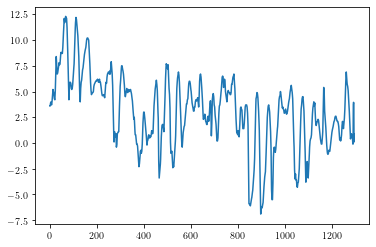

In [6]:
plt.plot(weatherdata[0])

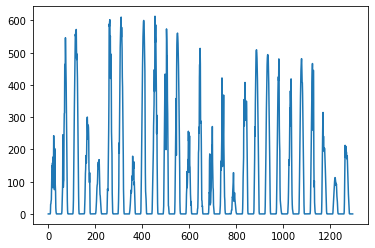

In [17]:
plt.plot(weatherdata[1])

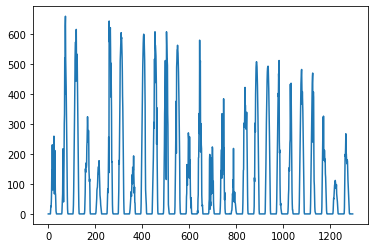

In [13]:
plt.plot(weatherdata[1])

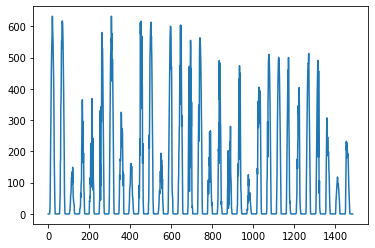

In [6]:
plt.plot(weatherdata[1])

In [11]:
data = pd.read_csv("../data-raw/inchannels15min.csv")
#data = pd.read_csv("../data-raw/inchannels15min.csv")
data = data[(data["time"] > "2021-03-01 00:00:00")]
data = data[(data["time"] < "2021-04-01 00:00:00")]
data = data[2::2]
#data["Ta"] = np.array(weatherdata[0])[::-1]
#data["Ps"] = np.array(weatherdata[1])[::-1]/1000

In [12]:
data

,time,HX_RC_ValveState_dh_ltech,HX_RC_TforwardSp_building_ltech,HX_RC_Treturn_building_ltech,HX_RC_Tforward_building_ltech,HX_RC_Treturn_dh_ltech,HX_RC_Tsensor_building_remoni,HX_RC_Treturn_building_remoni,HX_RC_Tforward_building_remoni,HX_VE_ValveState_dh_ltech,...,Room_C2.01_CO2__elsys,Room_C2.01_Humidity__elsys,Room_C2.01_Light__elsys,Room_C2.01_Motion__elsys,Room_C2.01_Temperature__elsys,Room_C0.15_CO2__elsys,Room_C0.15_Humidity__elsys,Room_C0.15_Light__elsys,Room_C0.15_Motion__elsys,Room_C0.15_Temperature__elsys
10177,2021-03-01 00:30:00+00:00,25.133960,60.0,46.884375,60.037190,47.765000,NaN,NaN,NaN,53.817923,...,435.333333,30.000000,0.0,0.0,21.366667,433.000000,30.0,0.0,0.0,21.600000
10179,2021-03-01 01:00:00+00:00,26.397250,60.0,46.030702,60.033028,46.950794,NaN,NaN,NaN,63.213235,...,441.666667,29.333333,0.0,0.0,21.233333,424.333333,30.0,0.0,0.0,21.633333
10181,2021-03-01 01:30:00+00:00,26.256607,60.0,45.821311,60.085593,46.713559,NaN,NaN,NaN,54.711478,...,441.333333,29.000000,0.0,0.0,21.100000,421.666667,30.0,0.0,0.0,21.700000
10183,2021-03-01 02:00:00+00:00,26.223397,60.0,46.106542,59.944444,46.976577,NaN,NaN,NaN,61.722000,...,435.000000,30.000000,0.0,0.0,21.066667,424.000000,30.0,0.0,0.0,21.666667
10185,2021-03-01 02:30:00+00:00,27.391228,60.0,46.494000,60.097196,47.359633,NaN,NaN,NaN,58.048686,...,430.000000,30.000000,0.0,0.0,21.000000,414.666667,30.0,0.0,0.0,21.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13141,2021-03-31 21:30:00+00:00,4.284093,60.0,39.877500,61.413103,44.756637,NaN,NaN,NaN,9.334650,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13143,2021-03-31 22:00:00+00:00,2.270334,60.0,34.203008,64.986667,55.458594,NaN,NaN,NaN,14.528925,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13145,2021-03-31 22:30:00+00:00,6.070972,60.0,35.094828,60.658503,48.788636,NaN,NaN,NaN,4.421699,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13147,2021-03-31 23:00:00+00:00,4.003507,60.0,31.491892,63.228788,50.717886,NaN,NaN,NaN,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


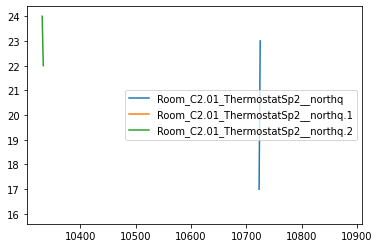

In [147]:
data[data.columns[data.columns.str.contains("Room_C2.01_ThermostatSp2__northq")]].plot()

In [7]:
proccessed_data, nan_count = load_building_data(weatherdata[0][:-1], weatherdata[1][:-1])

<home>\Anaconda3\lib\site-packages\ipykernel_launcher.py:166: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<home>\Anaconda3\lib\site-packages\ipykernel_launcher.py:169: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


Room_C0.01_Temperature__icmeter
Room_C1.02_Temperature__elsys


<home>\Anaconda3\lib\site-packages\ipykernel_launcher.py:210: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


Room_C1.00_Temperature__elsys
Room_C1.04_Temperature__elsys
Room_C1.03_Temperature__elsys
Room_C1.07_Temperature__elsys
Room_C1.09_Temperature__elsys
Room_C1.08_Temperature__elsys
Room_C1.12_Temperature__elsys
Room_C0.13_Temperature__elsys
Room_C0.11_Temperature__elsys
Room_C0.07A_Temperature__elsys
Room_C0.08_Temperature__elsys
Room_C0.07_Temperature__elsys
Room_C0.06_Temperature__elsys
Room_C2.04_Temperature__elsys
Room_C2.01_Temperature__elsys
Room_C0.15_Temperature__elsys


In [137]:
nan_count

array([ 0., 12., 13., 12., 14., 14., 13., 13., 13., 13., 15., 13., 13.,
       15., 13., 15., 14., 13.])

In [138]:
nan_count

array([ 0., 12., 13., 12., 14., 14., 13., 13., 13., 13., 15., 13., 13.,
       15., 13., 15., 14., 13.])

In [139]:
proccessed_data

,time,Room_C0.01_Temperature__icmeter,Room_C1.08_ThermostatSp2__northq,Room_C0.04_ThermostatSp2__northq,Room_C0.07_ThermostatSp2__northq,Room_C1.09_ThermostatSp2__northq,Room_C0.11_ThermostatSp2__northq,Room_C0.12_ThermostatSp2__northq,Room_C0.15_ThermostatSp2__northq,Room_C0.14_ThermostatSp2__northq,...,Ta_minus_Ti_C2.04,Tfor_minus_Ti_C2.04,Tset_minus_Ti_C2.01,Tset_C2.01,Ta_minus_Ti_C2.01,Tfor_minus_Ti_C2.01,Tset_minus_Ti_C0.15,Tset_C0.15,Ta_minus_Ti_C0.15,Tfor_minus_Ti_C0.15
0,2021-03-01 00:30:00+00:00,22.883333,22.0,22.0,22.0,22.0,22.0,22.0,22.0,22.0,...,-21.100000,38.800000,0.633333,22.0,-21.266667,38.633333,0.400000,22.0,-21.500000,38.400000
1,2021-03-01 01:00:00+00:00,22.570000,22.0,22.0,22.0,22.0,22.0,22.0,22.0,22.0,...,-17.350000,38.800000,0.766667,22.0,-17.383333,38.766667,0.366667,22.0,-17.783333,38.366667
2,2021-03-01 01:30:00+00:00,22.536667,22.0,22.0,22.0,22.0,22.0,22.0,22.0,22.0,...,-17.250000,38.800000,0.900000,22.0,-17.150000,38.900000,0.300000,22.0,-17.750000,38.300000
3,2021-03-01 02:00:00+00:00,22.583333,22.0,22.0,22.0,22.0,22.0,22.0,22.0,22.0,...,-17.350000,38.900000,0.933333,22.0,-17.316667,38.933333,0.333333,22.0,-17.916667,38.333333
4,2021-03-01 02:30:00+00:00,22.643333,22.0,22.0,22.0,22.0,22.0,22.0,22.0,22.0,...,-21.300000,38.800000,1.000000,22.0,-21.100000,39.000000,0.333333,22.0,-21.766667,38.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1290,2021-03-27 21:30:00+00:00,24.666667,23.0,22.0,23.0,23.0,23.0,22.0,23.0,22.0,...,-18.583333,37.466667,0.133333,22.0,-17.916667,38.133333,-0.100000,23.0,-19.150000,36.900000
1291,2021-03-27 22:00:00+00:00,24.633333,23.0,22.0,23.0,23.0,23.0,22.0,23.0,22.0,...,-18.666667,37.433333,0.100000,22.0,-18.000000,38.100000,-0.133333,23.0,-19.233333,36.866667
1292,2021-03-27 22:30:00+00:00,24.616667,23.0,22.0,23.0,23.0,23.0,23.0,23.0,23.0,...,-18.650000,37.600000,0.100000,22.0,-18.150000,38.100000,0.000000,23.0,-19.250000,37.000000
1293,2021-03-27 23:00:00+00:00,24.583333,23.0,22.0,23.0,23.0,23.0,23.0,23.0,23.0,...,-18.766667,37.633333,0.166667,22.0,-18.233333,38.166667,-0.133333,23.0,-19.533333,36.866667


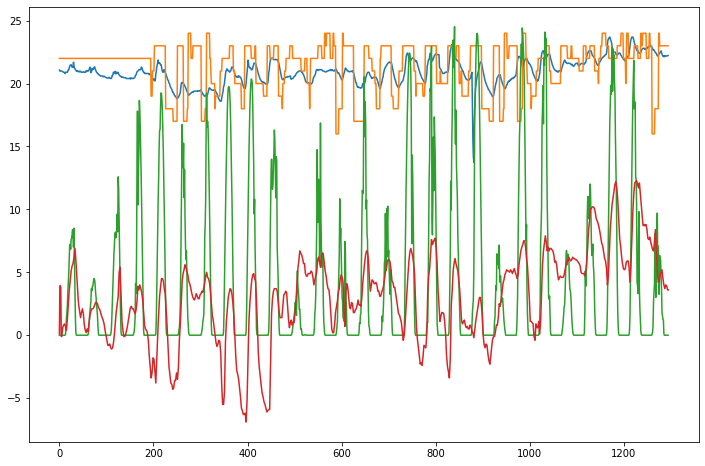

In [52]:
room_name = "1.00"
plt.figure(figsize=(12,8))
plt.plot(proccessed_data["Room_C"+room_name+"_Temperature__elsys"])
plt.plot(proccessed_data["Room_C"+room_name+"_ThermostatSp2__northq"])
plt.plot(proccessed_data["Ps"]*1000/25)
plt.plot(proccessed_data["Ta"])

In [44]:
proccessed_data.columns

Index(['time', 'Room_C0.01_Temperature__icmeter',
       'Room_C1.08_ThermostatSp2__northq', 'Room_C0.04_ThermostatSp2__northq',
       'Room_C0.07_ThermostatSp2__northq', 'Room_C1.09_ThermostatSp2__northq',
       'Room_C0.11_ThermostatSp2__northq', 'Room_C0.12_ThermostatSp2__northq',
       'Room_C0.15_ThermostatSp2__northq', 'Room_C0.14_ThermostatSp2__northq',
       'Room_C0.13_ThermostatSp2__northq', 'Room_C0.05_ThermostatSp2__northq',
       'Room_C0.03_ThermostatSp2__northq', 'Room_C0.02_ThermostatSp2__northq',
       'Room_C0.01_ThermostatSp2__northq', 'Room_C0.00_ThermostatSp2__northq',
       'Room_C1.13_ThermostatSp2__northq', 'Room_C1.12_ThermostatSp2__northq',
       'Room_C2.04_ThermostatSp2__northq', 'Room_C2.03_ThermostatSp2__northq',
       'Room_C2.01_ThermostatSp2__northq', 'Room_C0.08_ThermostatSp2__northq',
       'Room_C1.02_ThermostatSp2__northq', 'Room_C1.00_ThermostatSp2__northq',
       'Room_C1.03_ThermostatSp2__northq', 'Room_C0.06_ThermostatSp2__northq',
  

# Fitting ARX models to the data

Data visualisation

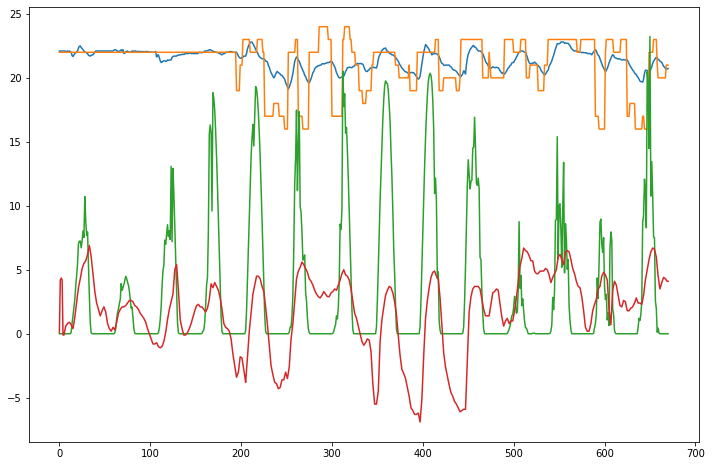

In [186]:
room_name = "0.07"
plt.figure(figsize=(12,8))
plt.plot(proccessed_data["Room_C"+room_name+"_Temperature__elsys"])
plt.plot(proccessed_data["Room_C"+room_name+"_ThermostatSp2__northq"])
plt.plot(proccessed_data["Ps"]*1000/25)
plt.plot(proccessed_data["Ta"])

In [13]:
proccessed_data["Ta_minus_Ti_C0.07"]

0     -22.000000
1     -16.366667
2     -16.800000
3     -17.300000
4     -22.200000
         ...    
522   -15.850000
523   -16.333333
524   -16.366667
525   -16.400000
526   -16.300000
Name: Ta_minus_Ti_C0.07, Length: 527, dtype: float64

In [241]:
roomname = "1.08"
endog_name = "Room_C" + roomname + "_Temperature__elsys"
exog_names = ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
Nd = 4
y = proccessed_data[endog_name][Nd:].to_numpy()
bspline_order = 8
bsplines_bf = construct_bspline_basisfunctions(bspline_order = bspline_order)
params0 = np.concatenate(([1, 0], np.ones((bspline_order+1,))), axis=0)

bounds = [(0.2,5),(-10,10)]
for i in range(bspline_order + 1):
    bounds.append((-10,10))
bounds = tuple(bounds)

res = optim.minimize(fit_splines_and_thermostat_parameters, params0, bounds=bounds, args=(proccessed_data, endog_name, exog_names, Nd, bsplines_bf), method="SLSQP") #, method="trust-constr" ... ,method="SLSQP"

In [242]:
res # trust-constr method

     fun: 6.160202589052422
     jac: array([ 6.51478767e-05, -3.27229500e-05,  0.00000000e+00,  5.96046448e-07,
        9.17911530e-06,  9.53674316e-06, -1.63912773e-04, -5.76376915e-05,
       -9.83476639e-06, -1.32322311e-05, -2.44379044e-06])
 message: 'Optimization terminated successfully'
    nfev: 901
     nit: 74
    njev: 74
  status: 0
 success: True
       x: array([  1.0503535 ,  -1.20915831,   1.        ,   0.99227848,
       -10.        ,  -0.27458898,  -1.54266672,   2.73868678,
        -1.35625178,   1.01917698,   0.99989516])

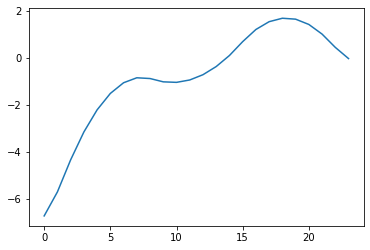

In [243]:
bspline_coef = res["x"][2:]
plt.plot((bsplines_bf@bspline_coef)[12:-12])

In [244]:
avg_solar = np.zeros((48,))
for i in range(avg_solar.shape[0]):
    avg_solar[i] = np.mean(proccessed_data["Ps"][i::48])

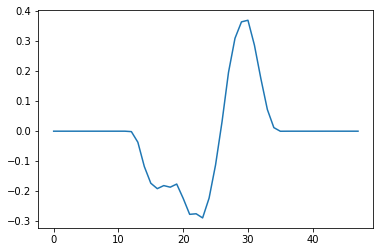

In [245]:
#plt.plot(avg_solar)
plt.plot(np.multiply((bsplines_bf@bspline_coef), avg_solar))

In [246]:
X_opt = construct_design_matrix_with_parameters(Nd, proccessed_data, endog_name, exog_names, res["x"][:2], res["x"][2:], bsplines_bf)

theta_opt = np.linalg.inv(X_opt.T@X_opt).T@(X_opt.T@y)
theta_opt

array([ 1.40250564e+00, -4.34201982e-01,  7.27588901e-02, -4.32342608e-02,
       -2.11275775e-02,  2.61401788e-02, -3.44830081e-03, -1.82185049e-03,
       -1.13518065e-01, -1.19546702e-02, -1.46728464e-01, -6.26696867e-02,
       -2.67206329e-03,  5.30347284e-04,  3.83306752e-04,  4.73143071e-03])

In [247]:
print(sum(theta_opt[:Nd]))
print(sum(theta_opt[Nd:2*Nd]))
print(sum(theta_opt[2*Nd:3*Nd]))
print(sum(theta_opt[3*Nd:4*Nd]))

0.9978282891810153
-0.00025754998831684084
-0.33487088608507065
0.0029730214591122683


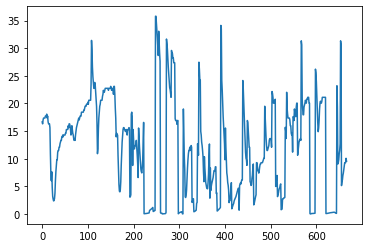

In [248]:
plt.plot(X_opt[:,-1])

In [249]:
Y0 = proccessed_data[endog_name][:Nd]
predlength = len(proccessed_data[endog_name]) - Nd
#redlength = 20
pred_exog = X_opt

preds = predict_multistep_ARX_model(theta_opt, Y0, predlength, pred_exog)

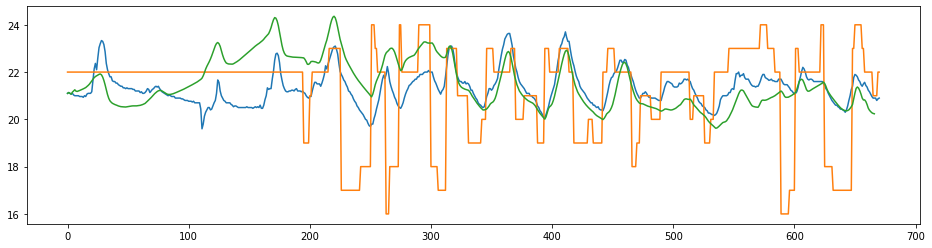

In [250]:
plt.figure(figsize=(16,4))
plt.plot(proccessed_data[endog_name])
plt.plot(proccessed_data["Room_C0.06_ThermostatSp2__northq"])
plt.plot(preds)

# Automatic order selection

In [87]:
def fit_ARX_model_order(endog_name, exog_names, b_spline_order, criterion="bic", _Nend=None, _spline_bounds=10):
    '''
    Estimates the optimal order of a multi-room model.
    
    X: the design matrix with both endo- and exogenous variables
    endog_name: the name of the endogenous variables in a pandas dataframe
    exog_names: the names of the exogenous variables in a pandas dataframe
    criterion: the information criterion to base the model selection on. Options right now is either "aic" or "bic". Default is BIC.
    Nend: an index in the data to split it into two parts. If Nend is different from None, only data[:Nend] will be used for parameter estimation
    '''
    
    if criterion == "bic":
        def criterion(_S, _Nparams, _N):
            return _N*np.log(_S) + _Nparams*np.log(_N)
    elif criterion == "aic":
        def criterion(_S, _Nparams, _N):
            return _N*np.log(_S) + 2*_Nparams
    else:
        raise Exception("criterion-argument must be either AIC or BIC. See help for exact notiation.")
    
    if _Nend is None:
        _Nend = len(proccessed_data)
    
    c0 = np.inf
    _order = 1
    N = len(proccessed_data)
    _bsplines_bf = construct_bspline_basisfunctions(n_bsplines = b_spline_order)
    
    while True:
        #_p0 = (1, 0)
        _p0 = np.concatenate(([1, 0], np.ones((b_spline_order+1,))), axis=0)
        _bounds = [(0.2,5),(-_spline_bounds,_spline_bounds)]
        for i in range(b_spline_order + 1):
            _bounds.append((-_spline_bounds,_spline_bounds))
        _bounds = tuple(_bounds)
        _res = optim.minimize(fit_splines_and_thermostat_parameters, _p0, bounds=_bounds,\
                     args=(proccessed_data, endog_name, exog_names, _order, _bsplines_bf), method="SLSQP")
        #X = construct_design_matrix(_order, endog_name, exog_names, params=_res["x"])[:_Nend-_order,:]
        X = construct_design_matrix_with_parameters(_order, proccessed_data, endog_name, exog_names, _res["x"][:2], _res["x"][2:], _bsplines_bf)
        y = proccessed_data[endog_name][_order:_Nend]
        theta = np.linalg.inv(X.T@X)@(X.T@y)
        S = (y - X@theta).T@(y - X@theta)
        
        c = criterion(S, len(theta), len(y))
        if c > c0:
            _order = _order - 1
            break
        c0 = c
        _order = _order + 1
        print(c)
        _res_previous = copy.deepcopy(_res)
    
    #_res = optim.minimize(fit_ARX_model_thermostat, _p0, bounds=((0.1,7),(-10,10)), args=(endog_name, exog_names, _order))
    #_res = optim.minimize(fit_splines_and_thermostat_parameters, _p0, bounds=_bounds,\
    #                 args=(proccessed_data, endog_name, exog_names, _order, _bsplines_bf), method="SLSQP")
    #_X = construct_design_matrix(_order, endog_name, exog_names, params=_res["x"])[:_Nend-_order,:]
    #_X_pred = construct_design_matrix(_order, endog_name, exog_names, params=_res["x"])
    _X = construct_design_matrix_with_parameters(_order, proccessed_data, endog_name, exog_names, _res_previous["x"][:2], _res["x"][2:], _bsplines_bf)[:_Nend-_order,:]
    _X_pred = construct_design_matrix_with_parameters(_order, proccessed_data, endog_name, exog_names, _res_previous["x"][:2], _res["x"][2:], _bsplines_bf)
    _y = proccessed_data[endog_name][_order:_Nend]
    _theta = np.linalg.inv(_X.T@_X)@(_X.T@_y)
    _S = (_y - _X@_theta).T@(_y - _X@_theta)
    
    return _theta, _res, _S, _order, _X_pred, c

In [29]:
roomname = "1.04"
endog_name = "Room_C" + roomname + "_Temperature__elsys"
exog_names = ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
bspline_order = 9

theta_opt, res_opt, S_opt, Nd_opt, X_pred_opt, c_opt = fit_ARX_model_order(endog_name, exog_names, bspline_order, criterion="bic", _Nend=None, _spline_bounds=40)

1272.0369351319825
1261.9848768553998


In [213]:
theta_opt

array([ 1.04298155, -0.08284835, -0.03889783,  0.03939577, -0.42609896,
        0.33991417, -0.01593013,  0.03984434])

In [30]:
res_opt

     fun: 10.814929802805075
     jac: array([-6.28232956e-05, -2.50339508e-05,  0.00000000e+00,  0.00000000e+00,
       -4.17232513e-06,  1.50203705e-05,  6.67572021e-06, -2.75373459e-05,
       -8.22544098e-06,  3.57627869e-07, -1.28746033e-05, -3.81469727e-06])
 message: 'Optimization terminated successfully.'
    nfev: 905
     nit: 64
    njev: 64
  status: 0
 success: True
       x: array([  0.40494076,   7.68493737,   1.        ,   1.        ,
         2.10664501,  -0.93139594,  -0.42209647,  -5.23629686,
        10.38441082, -39.84028557,   1.00378046,   1.00627551])

In [31]:
Y0 = proccessed_data[endog_name][:Nd_opt]
predlength = len(proccessed_data[endog_name]) - Nd_opt
#redlength = 20
pred_exog = X_pred_opt

preds = predict_multistep_ARX_model(theta_opt, Y0, predlength, pred_exog)

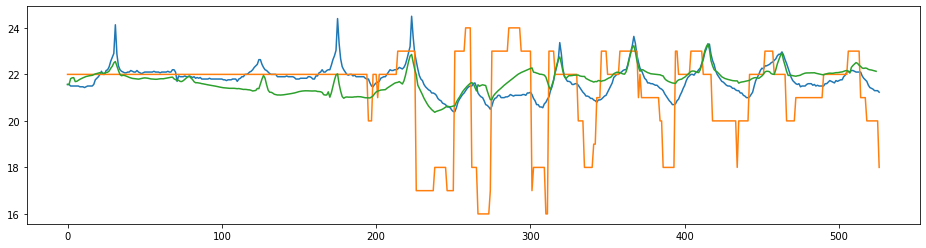

In [32]:
plt.figure(figsize=(16,4))
plt.plot(proccessed_data[endog_name])
plt.plot(proccessed_data["Room_C1.08_ThermostatSp2__northq"])
plt.plot(preds)

# Optimising over the knot-placement in the spline representation

In [11]:
def construct_bspline_basisfunctions_and_knot_placements(bspline_order=4, knot_params=None):
    _nt = bspline_order
    nx = 48
    x = np.linspace(0,24,10)
    y = np.ones((x.shape)) # the function we wish to interpolate
    if knot_params is None:
        t = np.linspace(x[0],x[-1],_nt)
        t = t[1:-1]
    else:
        t = np.cumsum(knot_params)
        

    tt = np.linspace(0.0, 24, nx)
    y_rep = si.splrep(x, y, t=t, k=2)

    y_i = si.splev(tt, y_rep)

    spl = np.zeros((nx,))
    bsplines = np.zeros((nx,_nt+1))

    for i in range(_nt+1):
        vec = np.zeros(_nt+1)
        vec[i] = 1.0
        y_list = list(y_rep)
        y_list[1] = vec.tolist()
        y_i = si.splev(tt, y_list) # your basis spline function
        bsplines[:,i] = y_i
    
    return bsplines

def fit_splines_knots_and_thermostat_parameters(params, _data, endog_name, exog_name, _order):
    '''
    Fits the B-spline representation and the thermostatic valve function parameters
    '''
    
    k = int((len(params[2:]) + 1)/2) # the B-spline order
    
    alpha0, Toffset0 = params[:2]
    _thermostatparams = alpha0, Toffset0
    _bsplinecoeff = params[2:2+k+1]
    _bsplineknots = params[2+k+1:]
    _basissplines = construct_bspline_basisfunctions_and_knot_placements(bspline_order=k, knot_params=_bsplineknots)
    
    _X = construct_design_matrix_with_parameters(_order, _data, endog_name, exog_names, _thermostatparams, _bsplinecoeff,  _basissplines)
    _y = _data[endog_name][_order:].to_numpy()
    
    _thetahat = np.linalg.inv(_X.T@_X).T@(_X.T@_y)
    _S = (_y - _X@_thetahat).T@(_y - _X@_thetahat)
    
    return _S

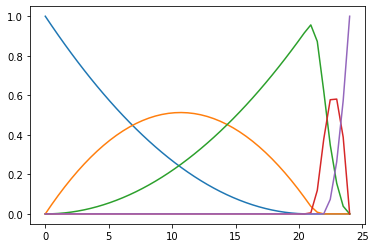

In [424]:
nt = 4 # the number of knots
nx = 48
x = np.linspace(0,24,10)
y = np.ones((x.shape)) # the function we wish to interpolate
t = np.linspace(x[0],x[-1],nt)
t = t[1:-1]
t[0] = 20.8
t[1] = 21.9

tt = np.linspace(0.0, 24, nx)
y_rep = si.splrep(x, y, t=t, k=2)

y_i = si.splev(tt, y_rep)

spl = np.zeros((nx,))
bsplines = np.zeros((nx,nt+1))

plt.figure()
for i in range(nt+1):
    vec = np.zeros(nt+1)
    vec[i] = 1.0
    y_list = list(y_rep)
    y_list[1] = vec.tolist()
    y_i = si.splev(tt, y_list) # your basis spline function
    #bsplines.append(y_i)
    bsplines[:,i] = y_i
    spl = spl + y_i*y_rep[1][i]
    plt.plot(tt, y_i)
    
#plt.savefig("basissplines.png", format="png", bbox_inches="tight")

In [12]:
def construct_linear_inequality_constraints(bspline_order):
    nknots = bspline_order - 2
    ub = 18*np.ones((nknots + 1))
    ub[0] = 22
    lb = 2*np.ones((nknots + 1))
    lb[0] = 5
    A = np.diag(np.ones((nknots,)))
    A = np.concatenate((np.ones((1,nknots)),A), axis=0)
    A = np.concatenate((np.zeros((A.shape[0],bspline_order + 1 + 2)),A), axis=1)
    return A, ub, lb

def construct_linear_inequality_constraints(bspline_order):
    nknots = bspline_order - 2
    ub = np.array([22])
    lb = np.array([5])
    #A = np.diag(np.ones((nknots,)))
    A = np.concatenate((np.zeros((1,bspline_order + 1 + 2)),np.ones((1,nknots))), axis=1)#np.ones((1,nknots))
    #A = np.concatenate((np.ones((1,nknots)),A), axis=0)
    #A = np.concatenate((np.zeros((A.shape[0],bspline_order + 1 + 2)),A), axis=1)
    return A, ub, lb

In [170]:
params0

array([1.  , 0.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 3.  ,
       3.75, 3.75, 3.75, 3.75])

In [171]:
construct_linear_inequality_constraints(bspline_order)

(array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.]]),
 array([22]),
 array([5]))

In [172]:
knots0

array([3.  , 3.75, 3.75, 3.75, 3.75])

In [174]:
roomname = "0.07"
endog_name = "Room_C" + roomname + "_Temperature__elsys"
exog_names = ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
Nd = 4
y = proccessed_data[endog_name][Nd:].to_numpy()
bspline_order = 6
#bsplines_bf = construct_bspline_basisfunctions(n_bsplines = n_bsplines, )
knots0 = np.concatenate(([3],np.diff(np.linspace(5,20,bspline_order-2))),axis=0)
params0 = np.concatenate(([1, 0], np.ones((bspline_order+1,)), knots0), axis=0)

bounds = [(0.2,5),(-30,30)]
for i in range(bspline_order + 1):
    bounds.append((-30,30))
for i in range(bspline_order - 2):
    bounds.append((1,18))
bounds = tuple(bounds)

A, ub, lb = construct_linear_inequality_constraints(bspline_order)
constraints = optim.LinearConstraint(A, lb, ub, keep_feasible=True)

#fit_splines_knots_and_thermostat_parameters(params0, proccessed_data, endog_name, exog_names, bspline_order)
#res = optim.minimize(fit_splines_and_thermostat_parameters, params0, bounds=bounds, args=(proccessed_data, endog_name, exog_names, Nd, bsplines_bf), method="SLSQP") #, method="trust-constr" ... ,method="SLSQP"
res = optim.minimize(fit_splines_knots_and_thermostat_parameters, params0, bounds=bounds, args=(proccessed_data, endog_name, exog_names, Nd), method="SLSQP",\
                     constraints=constraints) #, method="trust-constr" ... ,method="SLSQP"

In [175]:
res # trust-constr method

     fun: 3.8197222793198073
     jac: array([ 5.19904196e-02, -1.15633011e-05,  0.00000000e+00,  0.00000000e+00,
        4.74750996e-05,  2.25156546e-04,  4.04089689e-04,  1.14053488e-04,
       -1.02579594e-04,  7.49230385e-05,  5.54323196e-05,  2.90274620e-05,
        1.13636255e-04])
 message: 'Optimization terminated successfully'
    nfev: 441
     nit: 31
    njev: 31
  status: 0
 success: True
       x: array([ 0.2       ,  6.84831079,  1.        ,  1.03450914,  3.78258416,
       -0.21732167,  0.1131275 , -0.65632556,  1.06841728,  2.12891979,
        3.73935587,  6.24730945,  5.67619544])

In [176]:
bsplines_bf = construct_bspline_basisfunctions_and_knot_placements(bspline_order = bspline_order, knot_params=res["x"][-(bspline_order-2):])

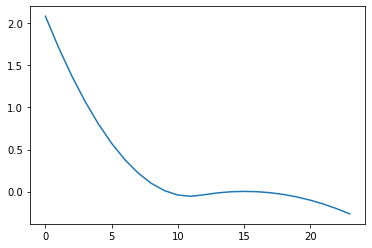

In [177]:
bspline_coef = res["x"][2:2+bspline_order+1]
plt.plot((bsplines_bf@bspline_coef)[12:-12])

In [178]:
avg_solar = np.zeros((48,))
for i in range(avg_solar.shape[0]):
    avg_solar[i] = np.mean(proccessed_data["Ps"][i::48])

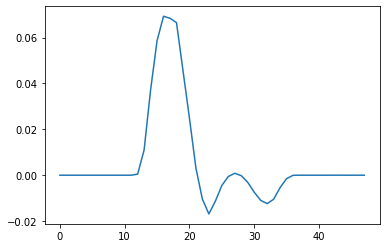

In [179]:
#plt.plot(avg_solar)
plt.plot(np.multiply((bsplines_bf@bspline_coef), avg_solar))

In [180]:
res["x"][:2]

array([0.2       , 6.84831079])

In [181]:
X_opt = construct_design_matrix_with_parameters(Nd, proccessed_data, endog_name, exog_names, res["x"][:2], bspline_coef, bsplines_bf)

theta_opt = np.linalg.inv(X_opt.T@X_opt).T@(X_opt.T@y)
theta_opt

array([ 1.38484961e+00, -3.14494638e-01, -3.96903802e-02, -4.95456771e-02,
       -9.57850047e-03,  2.47111507e-02, -2.06564269e-02,  6.68210742e-03,
        7.69116519e-01, -1.90366648e+00,  6.47626531e-01,  1.48235491e+00,
       -3.43195047e-03, -3.46157872e-03, -9.67012133e-04,  2.17372178e-02])

In [182]:
print(sum(theta_opt[:Nd]))
print(sum(theta_opt[Nd:2*Nd]))
print(sum(theta_opt[2*Nd:3*Nd]))
print(sum(theta_opt[3*Nd:4*Nd]))

0.9811189182696722
0.001158330772379479
0.99543148032717
0.013876676453172365


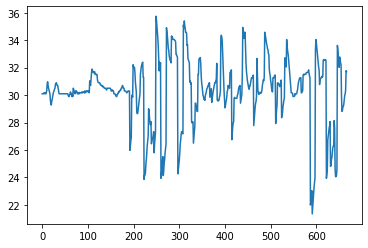

In [183]:
plt.plot(X_opt[:,-1])

In [184]:
Y0 = proccessed_data[endog_name][:Nd]
predlength = len(proccessed_data[endog_name]) - Nd
#redlength = 20
pred_exog = X_opt

preds = predict_multistep_ARX_model(theta_opt, Y0, predlength, pred_exog)

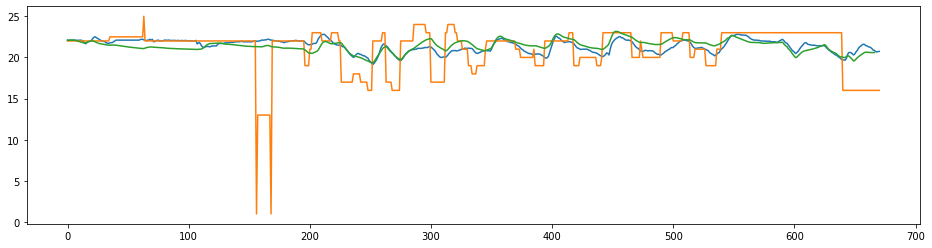

In [185]:
plt.figure(figsize=(16,4))
plt.plot(proccessed_data[endog_name])
plt.plot(proccessed_data["Room_C2.04_ThermostatSp2__northq"])
plt.plot(preds)

# Compare free B-spline knots to fixed

In [290]:
#################################
## FIXED KNOTS
#################################

roomname = "0.07"
endog_name = "Room_C" + roomname + "_Temperature__elsys"
exog_names = ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
Nd = 2
y = proccessed_data[endog_name][Nd:].to_numpy()
bspline_order = 5
bsplines_bf = construct_bspline_basisfunctions(bspline_order = bspline_order)
params0 = np.concatenate(([1, 0], np.ones((bspline_order+1,))), axis=0)

bounds = [(0.2,5),(-10,10)]
for i in range(bspline_order + 1):
    bounds.append((-10,10))
bounds = tuple(bounds)

res = optim.minimize(fit_splines_and_thermostat_parameters, params0, bounds=bounds, args=(proccessed_data, endog_name, exog_names, Nd, bsplines_bf), method="SLSQP") #, method="trust-constr" ... ,method="SLSQP"
print(res)

     fun: 6.718836254445384
     jac: array([ 2.22059965e-01, -2.83122063e-05,  0.00000000e+00, -1.86562538e-05,
       -5.54323196e-04, -5.36859035e-04,  4.35113907e-06,  5.85317612e-05])
 message: 'Optimization terminated successfully'
    nfev: 322
     nit: 35
    njev: 35
  status: 0
 success: True
       x: array([ 0.2       ,  5.22558375,  1.        ,  5.50479559, -0.32680158,
        0.26666816, -1.34318392,  0.98668761])


In [605]:
#################################
## FREE KNOTS
#################################

#roomname = "1.02"
#endog_name = "Room_C" + roomname + "_Temperature__elsys"
exog_names = ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
Nd = 2
y = proccessed_data[endog_name][Nd:].to_numpy()
bspline_order = 5
#knots0 = np.concatenate(([3],np.diff(np.linspace(5,20,bspline_order-2))),axis=0)
knots0 = np.diff(np.linspace(0,24,bspline_order)[:-1])
params0 = np.concatenate(([1, 0], np.ones((bspline_order+1,)), knots0), axis=0)

bounds = [(0.2,5),(-10,10)]
for i in range(bspline_order + 1):
    bounds.append((-10,10))
for i in range(bspline_order - 2):
    bounds.append((1.5,18))
bounds = tuple(bounds)

A, ub, lb = construct_linear_inequality_constraints(bspline_order)
constraints = optim.LinearConstraint(A, lb, ub, keep_feasible=True)

res_fk = optim.minimize(fit_splines_knots_and_thermostat_parameters, params0, bounds=bounds, args=(proccessed_data, endog_name, exog_names, Nd), method="SLSQP",\
                     constraints=constraints, options={"maxiter":500}) #, method="trust-constr" ... ,method="SLSQP"
print(res_fk)

     fun: 14.504803650756536
     jac: array([-2.40838528e-03,  4.63843346e-04,  0.00000000e+00,  4.37498093e-05,
        5.17356396e-03,  2.33905315e-02,  4.09591198e-03, -3.13520432e-05,
       -1.56760216e-04, -2.63810158e-04,  2.60472298e-04])
 message: 'Optimization terminated successfully.'
    nfev: 961
     nit: 72
    njev: 72
  status: 0
 success: True
       x: array([ 0.47521945, -1.31734808,  0.99954904,  5.98319903,  0.03201825,
       -0.01045492, -0.02803956,  1.53776266,  5.80843116,  2.88567284,
        7.34753306])


In [606]:
avg_solar = np.zeros((48,))
for i in range(avg_solar.shape[0]):
    avg_solar[i] = np.mean(proccessed_data["Ps"][i::48])

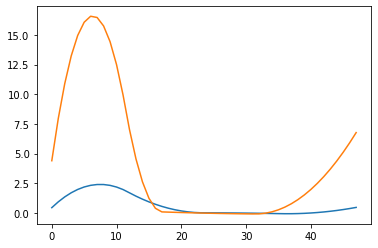

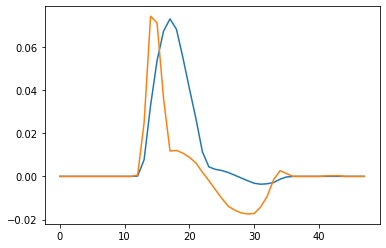

In [607]:
X_opt = construct_design_matrix_with_parameters(Nd, proccessed_data, endog_name, exog_names, res["x"][:2], res["x"][2:], bsplines_bf)
theta_opt = np.linalg.inv(X_opt.T@X_opt).T@(X_opt.T@y)
solar_sum = sum(theta_opt[2*Nd:3*Nd])
plt.figure()
bspline_coef = res["x"][2:]
bsplines_bf = construct_bspline_basisfunctions(bspline_order = bspline_order)
plt.plot(solar_sum*(bsplines_bf@bspline_coef))

bsplines_bf_fk = construct_bspline_basisfunctions_and_knot_placements(bspline_order = bspline_order, knot_params=res_fk["x"][-(bspline_order-2):])
bspline_coef_fk = res_fk["x"][2:2+bspline_order+1]
X_opt_fk = construct_design_matrix_with_parameters(Nd, proccessed_data, endog_name, exog_names, res_fk["x"][:2], bspline_coef_fk, bsplines_bf_fk)
theta_opt_fk = np.linalg.inv(X_opt_fk.T@X_opt_fk).T@(X_opt_fk.T@y)
solar_sum_fk = sum(theta_opt_fk[2*Nd:3*Nd])
plt.plot(solar_sum_fk*bsplines_bf_fk@bspline_coef_fk)

plt.figure()
plt.plot(solar_sum*np.multiply((bsplines_bf@bspline_coef), avg_solar))

plt.plot(solar_sum_fk*np.multiply((bsplines_bf_fk@bspline_coef_fk), avg_solar))

# Estimate thermostatic valve function using monotonic splines

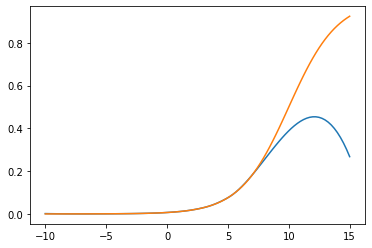

In [25]:
# Data to be interpolated.
x = np.array([-7, -5, -3, -1, 1, 3, 5, 7])
y = 1/(1 + np.exp(-0.5*(x - 10)))

# Create the interpolator.
interp = si.pchip(x, y)

xx = np.linspace(-10,15,100)
yy = interp(xx)

plt.plot(xx, yy)
plt.plot(xx,1/(1 + np.exp(-0.5*(xx - 10))))

In [15]:
def construct_design_matrix_with_parameters_and_valvesplines(_order, _data, endog_name, exog_names, _bsplinecoeff, basissplines, valveknots, valvefunctionvalues):
    '''
    params: are the thermostats parameters and are [slope, Toffset]
    valveknots: the knots points of the valve function t_i, i=0,...,N (where t_i<=t_i+1 for all i)
    valvefunctionvalues: the function values f_i, i=0,...,N
    '''
    
    DesignMatrix = np.zeros((len(_data)-_order, len(exog_names)*_order + _order))
    # part of design matrix that concerns the observations
    for j in range(_order):
        DesignMatrix[:,j] = _data[endog_name][_order-1-j:-(j+1)]
    
    # construct spline representation
    solarsplines = np.zeros((len(_data),))
    for i in range(len(_data)):
        solarsplines[i] = np.dot(basissplines[np.mod(i,basissplines.shape[0]),:],_bsplinecoeff)
    
    if valvefunctionvalues is not None:
        #alpha0, Toffset0 = thermostatparams
        _knots = np.concatenate(([-10],-10+np.cumsum(valveknots), [10]), axis=0)
        _funvalues = np.concatenate(([0], valvefunctionvalues, [1]), axis=0)
        #_valveinterp = si.pchip(_knots, valvefunctionvalues)
        _valveinterp = si.pchip(_knots, _funvalues)
        for j in range(len(exog_names)-1):
            if exog_names[j] == "Ps": # the case of Ps
                for i in range(_order):
                    DesignMatrix[:,_order + i + j*_order] = solarsplines[i:-_order+i] * _data[exog_names[j]][i:-_order+i]
            else:
                for i in range(_order):
                    DesignMatrix[:,_order + i + j*_order] = _data[exog_names[j]][i:-_order+i]
        
        Tset_string = "Tset_minus_Ti_" + exog_names[-1][-5:]
        Tfor_string = "Tfor_minus_Ti_" + exog_names[-1][-5:]
        for i in range(_order):
            #DesignMatrix[:,_order + i + (j+1)*_order] = 1/(1 + np.exp(-alpha0*(_data[Tset_string][i:-_order+i] + Toffset0)))*_data[Tfor_string][i:-_order+i]
            DesignMatrix[:,_order + i + (j+1)*_order] = _valveinterp(_data[Tset_string][i:-_order+i])*_data[Tfor_string][i:-_order+i]
    
    if valvefunctionvalues is None:
        for j in range(len(exog_names)):
            for i in range(_order):
                DesignMatrix[:,_order + i + j*_order] = _data[exog_names[j]][i:-_order+i]
    
    return DesignMatrix

def fit_splines_and_thermostat_parameters_valvesplines(params, _data, endog_name, exog_name, _order, basissplines):
    '''
    Fits the B-spline representation and the thermostatic valve function parameters
    '''
    
    _k = basissplines.shape[1] # the number of B-spline basis functions
    _N = int((len(params) - basissplines.shape[1])/2) # the number of function values and knot parameters
    
    #alpha0, Toffset0 = params[:2]
    #_thermostatparams = alpha0, Toffset0
    _bsplinecoeff = params[:_k]
    _valveknots = params[_k:_k+_N]
    _valvefunctionvalues = params[_k+_N:]
    
    _X = construct_design_matrix_with_parameters_and_valvesplines(_order, _data, endog_name, exog_names, _bsplinecoeff, basissplines, _valveknots, _valvefunctionvalues)
    _y = _data[endog_name][_order:].to_numpy()
    
    _thetahat = np.linalg.inv(_X.T@_X).T@(_X.T@_y)
    _S = (_y - _X@_thetahat).T@(_y - _X@_thetahat)
    
    return _S

def construct_linear_inequality_constraints_valve(bspline_order, _N_valve, _length):
    #ub = np.array(([_length - 1]))
    ub = np.concatenate(([_length - 1], np.zeros((_N_valve-1,))), axis=0)
    #lb = [_N_valve]
    lb = np.concatenate(([_N_valve], -1*np.ones((_N_valve-1,))), axis=0)
    A = np.concatenate((np.zeros((bspline_order+1,)), np.ones((_N_valve-2,)), np.zeros((_N_valve,))), axis=0)
    B = np.concatenate((np.eye(_N_valve-1), np.zeros((_N_valve-1,1))), axis=1) - np.concatenate((np.zeros((_N_valve-1,1)), 1*np.eye(_N_valve-1)), axis=1)
    C = np.concatenate((np.zeros((_N_valve-1 ,bspline_order+1 + _N_valve-2)), B), axis=1)
    A = np.concatenate((np.expand_dims(A,axis=1).T, C), axis=0)
    
    return A, ub, lb

def construct_linear_inequality_constraints_valve(bspline_order, _N_valve, _length):
    #ub = np.array(([_length - 1]))
    ub = np.concatenate(([_length - 1], np.zeros((_N_valve-3,))), axis=0)
    #lb = [_N_valve]
    lb = np.concatenate(([_N_valve], -1*np.ones((_N_valve-3,))), axis=0)
    A = np.concatenate((np.zeros((bspline_order+1,)), np.ones((_N_valve-2,)), np.zeros((_N_valve-2,))), axis=0)
    #print(A)
    B = np.concatenate((np.eye(_N_valve-3), np.zeros((_N_valve-3,1))), axis=1) - np.concatenate((np.zeros((_N_valve-3,1)), 1*np.eye(_N_valve-3)), axis=1)
    C = np.concatenate((np.zeros((_N_valve-3 ,bspline_order+1 + _N_valve-2)), B), axis=1)
    #print(B)
    #print(C)
    A = np.concatenate((np.expand_dims(A,axis=1).T, C), axis=0)
    
    return A, ub, lb

In [54]:
construct_linear_inequality_constraints_valve(4, 5, 20)

(array([[ 0.,  0.,  0.,  0.,  0.,  1.,  1.,  1.,  0.,  0.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1., -1.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1., -1.]]),
 array([19.,  0.,  0.]),
 array([ 5., -1., -1.]))

In [55]:
np.concatenate(([10], np.ones((6,))))

array([10.,  1.,  1.,  1.,  1.,  1.,  1.])

In [56]:
Mt = 4
np.concatenate((np.eye(Mt-1), np.zeros((Mt-1,1))), axis=1) - np.concatenate((np.zeros((Mt-1,1)), 1*np.eye(Mt-1)), axis=1)

array([[ 1., -1.,  0.,  0.],
       [ 0.,  1., -1.,  0.],
       [ 0.,  0.,  1., -1.]])

In [57]:
A.shape

NameError: name 'A' is not defined

In [166]:
params0.shape

(11,)

In [228]:
A.shape

(5, 16)

In [229]:
lb.shape

(5,)

In [230]:
ub.shape

(5,)

In [16]:
#################################
## FREE KNOTS
#################################

roomname = "1.09"
endog_name = "Room_C" + roomname + "_Temperature__elsys"
exog_names = ["Ta_minus_Ti_C" + roomname, "Ps", "Tfor_minus_Ti_C" + roomname]
Nd = 2
y = proccessed_data[endog_name][Nd:].to_numpy()
bspline_order = 4
N_valve = 5
bsplines_bf = construct_bspline_basisfunctions(bspline_order = bspline_order)
#knots0 = np.concatenate(([3],np.diff(np.linspace(5,20,bspline_order-2))),axis=0)
#knots0 = np.diff(np.linspace(0,24,bspline_order)[:-1])
valveknots0 = np.diff(np.linspace(-10,10,N_valve)[:-1]) # the valve knot parameters
valvefunctionvalues0 = np.array([0, 0.1, 0.9])
#params0 = np.concatenate(([1, 0], np.ones((bspline_order+1,)), knots0), axis=0)
params0 = np.concatenate((0.6*np.ones((bspline_order+1,)), valveknots0, valvefunctionvalues0), axis=0)

bounds = []
for i in range(bspline_order + 1):
    bounds.append((-10,10))
for i in range(N_valve - 2):
    bounds.append((0.05, 20 - N_valve))
for i in range(N_valve - 2):
    bounds.append((0, 1))
#for i in range(bspline_order - 2):
#    bounds.append((1.5,18))
bounds = tuple(bounds)

#A, ub, lb = construct_linear_inequality_constraints(bspline_order)
#constraints = optim.LinearConstraint(A, lb, ub, keep_feasible=True)
A, ub, lb = construct_linear_inequality_constraints_valve(bspline_order, N_valve, 20)
constraints_valve = optim.LinearConstraint(A, lb, ub, keep_feasible=True)

#res_fk = optim.minimize(fit_splines_knots_and_thermostat_parameters, params0, bounds=bounds, args=(proccessed_data, endog_name, exog_names, Nd), method="SLSQP",\
#                     constraints=constraints, options={"maxiter":500}) #, method="trust-constr" ... ,method="SLSQP"
res_valve = optim.minimize(fit_splines_and_thermostat_parameters_valvesplines, params0, bounds=bounds, args=(proccessed_data[:850], endog_name, exog_names, Nd, bsplines_bf), method="SLSQP",\
                     constraints=constraints_valve, options={"maxiter":500}) #, method="trust-constr" ... ,method="SLSQP"
print(res_valve)

     fun: 6.738382261950204
     jac: array([ 2.58088112e-05,  7.45058060e-06,  3.60608101e-05,  1.91926956e-05,
       -7.71284103e-05,  3.09884548e-04, -3.09348106e-05,  2.17139721e-04,
       -2.59446502e-02,  4.58127260e-03, -3.46899033e-05])
 message: 'Optimization terminated successfully.'
    nfev: 1066
     nit: 80
    njev: 80
  status: 0
 success: True
       x: array([ 0.57689483, -1.11331933, -0.50147705,  3.14853228,  0.61786821,
        0.89332665, 11.32486976,  4.63303409,  0.08330928,  0.50297551,
        0.91448856])


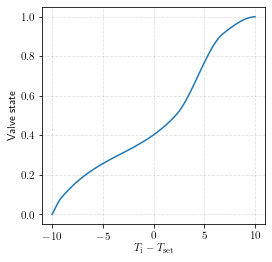

In [22]:
valveknots_opt = np.concatenate(([-10],-10+np.cumsum(res_valve["x"][bspline_order+1:bspline_order+1+N_valve-2]), [10]), axis=0)
functionvalue_opt = np.concatenate(([0], res_valve["x"][-(N_valve-2):], [1]), axis=0)

valveinterp_opt = si.pchip(valveknots_opt, functionvalue_opt)

xx = np.linspace(-10,10,100)
fig, ax = plt.subplots(1,1,figsize=(4,4))
yy = valveinterp_opt(xx)
plt.plot(xx,yy)
ax.tick_params(labelsize=11)
ax.set_xlabel("$T_{\mathrm{i}} - T_{\mathrm{set}}$", fontsize=11)
ax.set_ylabel("Valve state", fontsize=11)
ax.grid(alpha=0.4, linestyle="--")
#plt.savefig("figs/thermostatic_valve_function_C109.png", format="png", dpi=300, bbox_inches="tight")

In [1114]:
avg_solar = np.zeros((48,))
for i in range(avg_solar.shape[0]):
    avg_solar[i] = np.mean(proccessed_data["Ps"][i::48])

In [1115]:
np.linspace(0,24,13)

array([ 0.,  2.,  4.,  6.,  8., 10., 12., 14., 16., 18., 20., 22., 24.])

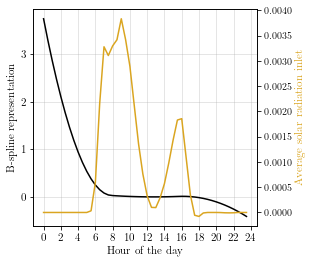

In [1123]:
#plt.plot(avg_solar)
fig, ax = plt.subplots(1,1,figsize=(4,4))
bspline_coef = res_valve["x"][:bspline_order+1]
ax.plot(bsplines_bf@bspline_coef, color="black")
ax2 = ax.twinx()
ax2.plot(np.multiply((bsplines_bf@bspline_coef), avg_solar), color="goldenrod")
ax.tick_params(labelsize=11)
ax.set_xticks(np.linspace(0,48,13))
ax.set_xticklabels(np.linspace(0,24,13, dtype=np.int))
ax.set_xlabel("Hour of the day", fontsize=11)
ax.set_ylabel("B-spline representation", fontsize=11)
ax2.set_ylabel("Average solar radiation inlet", color="goldenrod", fontsize=11)
ax.grid(alpha=0.4)
#plt.savefig("figs/solarradiation_splines_C100.pdf", format="pdf", bbox_inches="tight")

In [1119]:
valveknots_opt

array([-10.        ,   0.1989077 ,   2.80043019,  10.        ])

In [1120]:
#Xvalve_opt = construct_design_matrix_with_parameters(Nd, proccessed_data, endog_name, exog_names, res["x"][:2], res["x"][2:], bsplines_bf)
Xvalve_opt = construct_design_matrix_with_parameters_and_valvesplines(Nd, proccessed_data,endog_name, exog_names,res_valve["x"][:bspline_order+1],
                                                                      bsplines_bf, res_valve["x"][bspline_order+1:bspline_order+1+N_valve-2], res_valve["x"][-(N_valve-2):])
theta_valve_opt = np.linalg.inv(Xvalve_opt.T@Xvalve_opt)@(Xvalve_opt.T@y)
print(theta_valve_opt)

[ 1.51523705e+00 -5.19886149e-01  6.19232593e-04 -1.22766097e-03
 -1.23644438e+01  1.72608031e+01 -9.77457885e-04  4.28142920e-03]


In [1040]:
def predict_multistep_ARX_model(theta, _Y0, length, _Ta, _Ps, _Tset, _bsplinecoeff, _basissplines, _valveknots, _valvefunctionvalues):
    '''
    Predicts the evolution of the ARX system using the parameters in theta
    Y0 = [Y_p-1, ..., Y_0], where p is the order of the ARX model
    exog0 = [Ta_i-Ti, Ta_i-1-Ti-1, ..., Ps_i, Ps_i-1, ..., Tfor-Ti, Tfor-Ti-1, ...]
    '''
    #if length != exog.shape[0]:
    #    raise Exception("the length-argument must equal the length of the exogenous input")
    
    Nd = len(_Y0)
    
    # compute splines as a function of the time of the day before hand
    solarsplines = np.zeros((len(_Ps),))
    for i in range(len(_Ps)):
        solarsplines[i] = np.dot(_basissplines[np.mod(i,_basissplines.shape[0]),:],_bsplinecoeff)
    
    # compute the valve state function
    #_knots = np.concatenate(([-10],-10+np.cumsum(_valveknots), [10]), axis=0)
    _knots = _valveknots
    #_funvalues = np.concatenate(([0], _valvefunctionvalues, [1]), axis=0)
    _funvalues = _valvefunctionvalues
    _valveinterp = si.pchip(_knots, _funvalues)
    
    Y = np.zeros((length,))
    Y[:Nd] = _Y0
    
    for i in range(length-Nd):
        #print(Y[i:i+Nd])
        _exog = np.concatenate((_Ta[i:i+Nd] - Y[i:i+Nd], \
                                solarsplines[i:i+Nd]*_Ps[i:i+Nd], \
                                _valveinterp(_Tset[i:i+Nd] - Y[i:i+Nd])*(60 - Y[i:i+Nd])), axis=0)
        Y[i+Nd] = np.dot(Y[i:i+Nd], theta[:Nd][::-1]) + np.dot(theta[Nd:],_exog)
    
    return Y

Y0 = proccessed_data[endog_name][:Nd]
predlength = len(proccessed_data[endog_name]) - Nd
#redlength = 20
pred_exog = Xvalve_opt

#preds = predict_multistep_ARX_model(theta_valve_opt, Y0, predlength, pred_exog)
preds = predict_multistep_ARX_model(theta_valve_opt, Y0, predlength, proccessed_data["Ta"], proccessed_data["Ps"], proccessed_data["Tset_C"+roomname],\
                                   bspline_coef, bsplines_bf, valveknots_opt, functionvalue_opt)

Text(0, 0.5, 'Solar radiation [kW/m$^2$]')

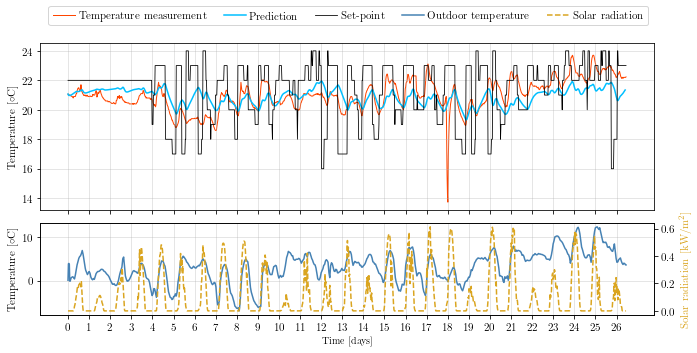

In [1041]:
plt.rc( 'text', usetex=True ) 
plt.rc('font',family = 'Times New Roman')

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(11,5), gridspec_kw={'height_ratios': [1.8, 1]})
fig.subplots_adjust(hspace=.1)
l1 = ax1.plot(proccessed_data[endog_name], color="orangered", linewidth=1, zorder=1)
l2 = ax1.plot(preds, color="deepskyblue", linestyle="-", zorder=2, linewidth=1.5)
l3 = ax1.plot(proccessed_data["Tset_C"+roomname], color="black", linewidth=0.8, zorder=3)
ax1.grid(alpha=0.4)
ax1.tick_params(axis="both", labelsize=11)
ax1.set_xticks(np.linspace(0,1272,27))
ax1.set_xticklabels([])
ax1.set_ylabel("Temperature [$\\circ$C]", fontsize=11)
#ax1.set_ylim(15,26)

l4 = ax2.plot(proccessed_data["Ta"], color="steelblue")
ax2.grid(alpha=0.4)
ax2.tick_params(axis="both", labelsize=11)
ax2.set_xticks(np.linspace(0,1272,27))
ax2.set_xticklabels(np.linspace(0,26,27, dtype=np.int))
ax22 = ax2.twinx()
l5 = ax22.plot(proccessed_data["Ps"], color="goldenrod", linestyle="--")
ax22.tick_params(axis="both", labelsize=11)
ax2.legend(l1+l2+l3+l4+l5,['Temperature measurement', 'Prediction', 'Set-point', 'Outdoor temperature', 'Solar radiation'],\
           loc='upper right', fontsize=11, ncol=5, bbox_to_anchor=(1,3.4), handletextpad=0.35, columnspacing=1.5)
ax2.set_xlabel("Time [days]")
ax2.set_ylabel("Temperature [$\\circ$C]", fontsize=11)
ax22.set_ylabel("Solar radiation [kW/m$^2$]", fontsize=11, color="goldenrod")
#plt.show()
#plt.savefig("figs/multisteppreds_C109.pdf", format="pdf", bbox_inches="tight")

# Make plot/illustration of Hermite splines for article

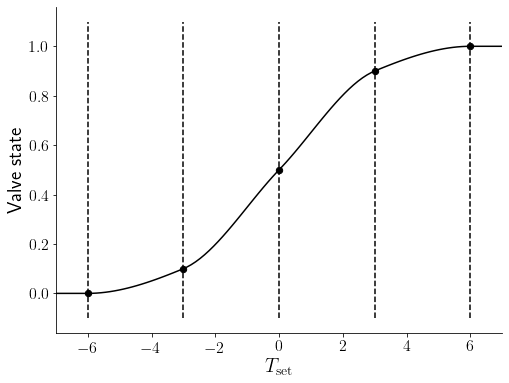

In [63]:
plt.rc('text', usetex=True)
valveknots_opt = np.array([-8, -6, -3, 0, 3, 6, 8])
functionvalue_opt = np.array([0,0,0.1,0.5,0.9,1,1])

valveinterp_opt = si.pchip(valveknots_opt, functionvalue_opt)

xx = np.linspace(-7,7,100)
yy = valveinterp_opt(xx)

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(xx,yy, color="black")
ax.scatter(valveknots_opt, functionvalue_opt, s=40, color="black")
ax.vlines(valveknots_opt, -0.1, 1.1, linestyle="dashed")
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_xlim(-7,7)
ax.tick_params(axis="both", labelsize=16)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.set_xlabel(r"$T_{\mathrm{set}}-T_{\mathrm{i}}$", fontsize=20)
ax.set_ylabel(r"Valve state", fontsize=20)#" - T_\\text{i}$")
#ax.xaxis.set_label_coords(1.05, -0.025)
#plt.savefig("figs/valve_splines_illustration.eps", format="eps", bbox_inches="tight")